# Supervised Lexical DGA Domain Detection



## 1. Imports and configuration

In [1]:
import os
import re
import math
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from collections import Counter
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

RANDOM_STATE = 42
DATA_PATH = "datasets/dga2.csv"
MODEL_DIR = "models"

FEATURE_COLUMNS = [
    "domain_length",
    "digit_count",
    "vowel_count",
    "consonant_count",
    "digit_ratio",
    "vowel_ratio",
    "unique_char_ratio",
    "entropy",
    "hyphen_count",
    "max_consonant_sequence"
]

EXPECTED_LABELS = {"benign", "dga"}
VOWEL_PATTERN = r"[aeiou]"
CONSONANT_PATTERN = r"[bcdfghjklmnpqrstvwxyz]"


## 2. Load and inspect the dataset

In [2]:
df = pd.read_csv(DATA_PATH)

required_columns = {"domain", "threat"}
missing_columns = required_columns - set(df.columns)
if missing_columns:
    raise ValueError(f"Dataset is missing required columns: {sorted(missing_columns)}")

print("First rows:")
display(df.head())

print("\\nDataset shape:", df.shape)
print("\\nMissing values:")
print(df[["domain", "threat"]].isnull().sum())

print("\\nOriginal class distribution:")
print(df["threat"].value_counts(dropna=False))

print("\\nDuplicate rows:", df.duplicated().sum())


First rows:


,domain,threat
0,ocymmekqogkw,dga
1,eohcbdibsjoiafxnrvddh,dga
2,myhandeczema,benign
3,deummagdbawse,dga
4,vipozacyqexib,dga


\nDataset shape: (16246006, 2)
\nMissing values:
domain    3
threat    0
dtype: int64
\nOriginal class distribution:
threat
dga       8261879
benign    7984127
Name: count, dtype: int64
\nDuplicate rows: 2


## 3. Clean the data

In [3]:
df = df.dropna(subset=["domain", "threat"]).copy()
df["domain"] = df["domain"].astype(str).str.lower().str.strip()
df["threat"] = df["threat"].astype(str).str.lower().str.strip()

# Remove empty domains and exact duplicate records.
df = df[df["domain"] != ""].drop_duplicates().reset_index(drop=True)

unexpected_labels = set(df["threat"].unique()) - EXPECTED_LABELS
if unexpected_labels:
    raise ValueError(
        f"Unexpected threat labels: {sorted(unexpected_labels)}. "
        f"Expected only {sorted(EXPECTED_LABELS)}."
    )

# A domain with conflicting labels cannot be assigned a reliable target.
domain_label_counts = df.groupby("domain")["threat"].nunique()
conflicting_domains = domain_label_counts[domain_label_counts > 1]
conflicting_domain_names = set(conflicting_domains.index)

print("Unique domains before conflict removal:", df["domain"].nunique())
print("Domains with conflicting labels:", len(conflicting_domain_names))

if conflicting_domain_names:
    display(
        df[df["domain"].isin(conflicting_domain_names)]
        .sort_values("domain")
        .head(30)
    )

# Exclude every occurrence of a conflicting domain.
df = df[~df["domain"].isin(conflicting_domain_names)].copy()

# Keep one row per domain so the same domain cannot appear in multiple splits.
df = (
    df.sort_values(["domain", "threat"])
      .drop_duplicates(subset=["domain"], keep="first")
      .reset_index(drop=True)
)

print("\nCleaned dataset shape:", df.shape)
print("Unique domains after cleaning:", df["domain"].nunique())
print("\nCleaned class distribution:")
print(df["threat"].value_counts())
print("Remaining duplicate domains:", int(df["domain"].duplicated().sum()))

Unique domains before conflict removal: 16246003
Domains with conflicting labels: 0

Cleaned dataset shape: (16246003, 2)
Unique domains after cleaning: 16246003

Cleaned class distribution:
threat
dga       8261879
benign    7984124
Name: count, dtype: int64
Remaining duplicate domains: 0


## 4. Create a balanced sample

In [4]:
class_counts = df["threat"].value_counts()
if not EXPECTED_LABELS.issubset(set(class_counts.index)):
    raise ValueError("Both 'benign' and 'dga' classes must be present.")

SAMPLES_PER_CLASS = 10_000
if (class_counts < SAMPLES_PER_CLASS).any():
    raise ValueError(
        f"At least {SAMPLES_PER_CLASS:,} unique records per class are required "
        f"after duplicate and conflicting-label removal. "
        f"Available counts: {class_counts.to_dict()}"
    )

sample = (
    df.groupby("threat", group_keys=False)
      .sample(n=SAMPLES_PER_CLASS, random_state=RANDOM_STATE)
      .sample(frac=1, random_state=RANDOM_STATE)
      .reset_index(drop=True)
)

print("Sample shape:", sample.shape)
print("\nSample class distribution:")
print(sample["threat"].value_counts())
print("Unique sampled domains:", sample["domain"].nunique())
display(sample.head())

Sample shape: (20000, 2)

Sample class distribution:
threat
dga       10000
benign    10000
Name: count, dtype: int64
Unique sampled domains: 20000


,domain,threat
0,zodircudqwj,dga
1,mayahtt,benign
2,ktcquail,benign
3,advgyn,benign
4,vchcwndc,dga


## 5. Define lexical feature extraction

In [5]:
def calculate_entropy(domain: str) -> float:
    """Calculate Shannon character entropy in bits per character."""
    if not domain:
        return 0.0

    counts = Counter(domain)
    length = len(domain)
    return -sum(
        (count / length) * math.log2(count / length)
        for count in counts.values()
    )


def max_consonant_sequence(domain: str) -> int:
    """Return the longest uninterrupted run of ASCII English consonants."""
    sequences = re.findall(CONSONANT_PATTERN + r"+", domain)
    return max((len(sequence) for sequence in sequences), default=0)


def extract_domain_features(domain: str) -> dict:
    """Extract the same ten lexical features used by model training."""
    if pd.isna(domain):
        domain = ""
    domain = str(domain).lower().strip()

    length = len(domain)
    digit_count = sum(char.isdigit() for char in domain)
    vowel_count = len(re.findall(VOWEL_PATTERN, domain))
    consonant_count = len(re.findall(CONSONANT_PATTERN, domain))
    hyphen_count = domain.count("-")

    return {
        "domain_length": length,
        "digit_count": digit_count,
        "vowel_count": vowel_count,
        "consonant_count": consonant_count,
        "digit_ratio": digit_count / length if length else 0.0,
        "vowel_ratio": vowel_count / length if length else 0.0,
        "unique_char_ratio": len(set(domain)) / length if length else 0.0,
        "entropy": calculate_entropy(domain),
        "hyphen_count": hyphen_count,
        "max_consonant_sequence": max_consonant_sequence(domain)
    }


feature_frame = pd.DataFrame(
    sample["domain"].apply(extract_domain_features).tolist(),
    index=sample.index
)

sample = pd.concat([sample, feature_frame], axis=1)

# Keep the feature order explicit and stable.
X = sample[FEATURE_COLUMNS].copy()
y = sample["threat"].map({"benign": 0, "dga": 1}).astype(int)

print("Feature matrix shape:", X.shape)
display(sample[["domain", "threat"] + FEATURE_COLUMNS].head())


Feature matrix shape: (20000, 10)


,domain,threat,domain_length,digit_count,vowel_count,consonant_count,digit_ratio,vowel_ratio,unique_char_ratio,entropy,hyphen_count,max_consonant_sequence
0,zodircudqwj,dga,11,0,3,8,0.0,0.272727,0.909091,3.277613,0,4
1,mayahtt,benign,7,0,2,5,0.0,0.285714,0.714286,2.235926,0,3
2,ktcquail,benign,8,0,3,5,0.0,0.375000,1.000000,3.000000,0,4
3,advgyn,benign,6,0,1,5,0.0,0.166667,1.000000,2.584963,0,5
4,vchcwndc,dga,8,0,0,8,0.0,0.000000,0.750000,2.405639,0,8


## 6. Exploratory feature analysis

In [6]:
print("Feature summary:")
display(sample[FEATURE_COLUMNS].describe())

print("\\nMean feature values by class:")
display(sample.groupby("threat")[FEATURE_COLUMNS].mean().T)


Feature summary:


,domain_length,digit_count,vowel_count,consonant_count,digit_ratio,vowel_ratio,unique_char_ratio,entropy,hyphen_count,max_consonant_sequence
count,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000
mean,13.525500,0.766400,3.994800,8.698850,0.060674,0.292913,0.758373,3.091895,0.065400,3.882900
std,5.883101,2.267595,2.595748,4.127676,0.191880,0.144926,0.141415,0.503553,0.291937,2.575057
min,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.200000,-0.000000,0.000000,0.000000
25%,9.000000,0.000000,2.000000,6.000000,0.000000,0.187500,0.666667,2.750000,0.000000,2.000000
50%,12.000000,0.000000,4.000000,8.000000,0.000000,0.312500,0.750000,3.121928,0.000000,3.000000
75%,17.000000,0.000000,5.000000,11.000000,0.000000,0.400000,0.857143,3.422487,0.000000,5.000000
max,44.000000,28.000000,21.000000,29.000000,1.000000,0.833333,1.000000,4.649115,4.000000,24.000000


\nMean feature values by class:


threat,benign,dga
domain_length,11.789400,15.261600
digit_count,0.434100,1.098700
vowel_count,4.252000,3.737600
consonant_count,6.972400,10.425300
digit_ratio,0.070258,0.051090
vowel_ratio,0.344498,0.241327
unique_char_ratio,0.764890,0.751856
entropy,2.921383,3.262407
hyphen_count,0.130800,0.000000
max_consonant_sequence,2.470900,5.294900


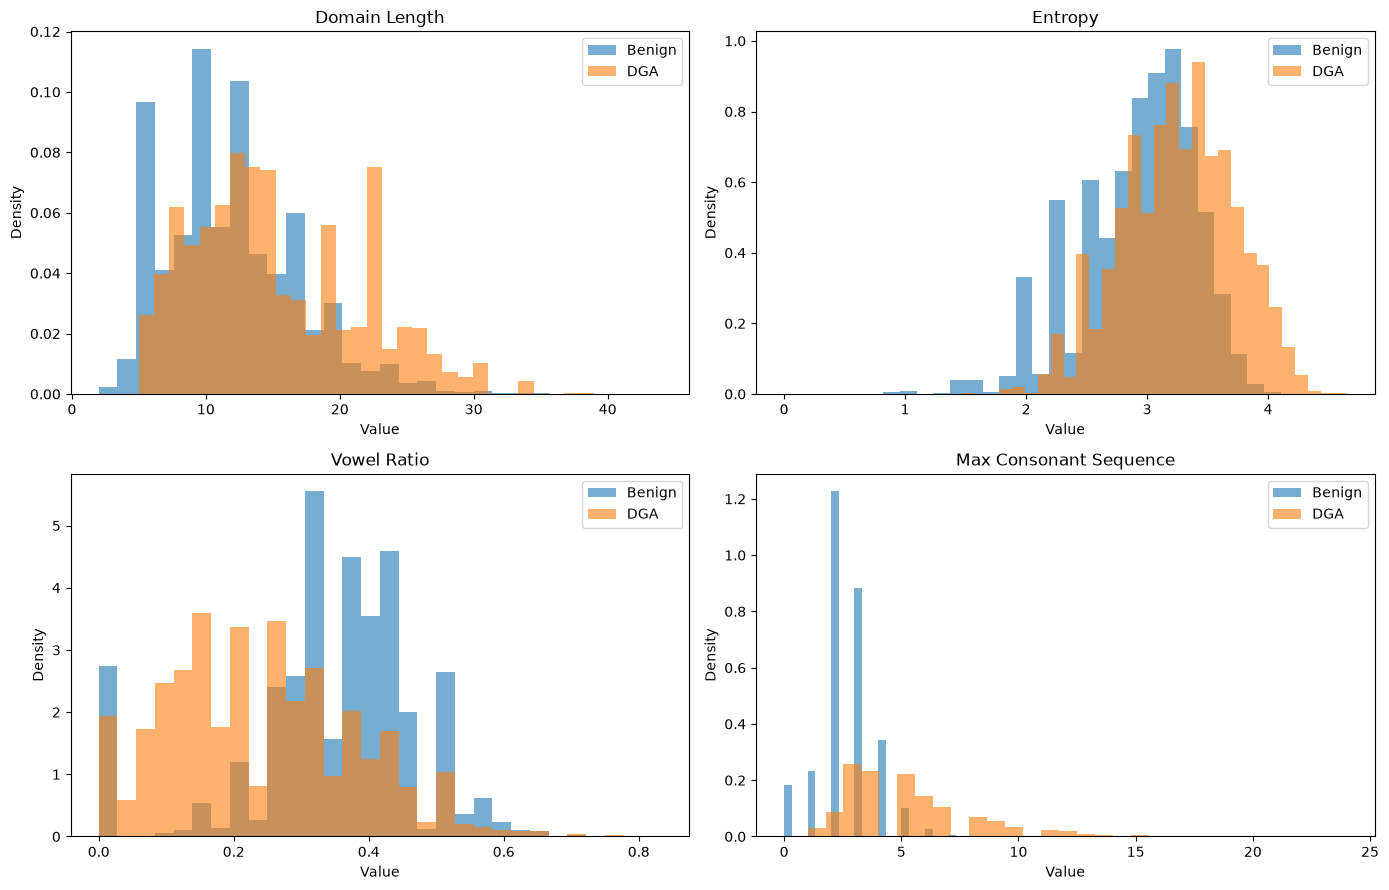

In [7]:
features_to_plot = [
    "domain_length",
    "entropy",
    "vowel_ratio",
    "max_consonant_sequence"
]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for ax, feature in zip(axes.flatten(), features_to_plot):
    benign = sample.loc[sample["threat"] == "benign", feature]
    dga = sample.loc[sample["threat"] == "dga", feature]

    ax.hist(benign, bins=30, alpha=0.6, density=True, label="Benign")
    ax.hist(dga, bins=30, alpha=0.6, density=True, label="DGA")
    ax.set_title(feature.replace("_", " ").title())
    ax.set_xlabel("Value")
    ax.set_ylabel("Density")
    ax.legend()

plt.tight_layout()
plt.show()


In [8]:
correlation_matrix = sample[FEATURE_COLUMNS].corr()

upper_triangle = correlation_matrix.where(
    np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
)
correlation_pairs = (
    upper_triangle.stack()
    .sort_values(key=abs, ascending=False)
)

print("Feature correlations (largest absolute correlations first):")
display(correlation_pairs)


Feature correlations (largest absolute correlations first):


domain_length           consonant_count           0.866066
                        entropy                   0.789863
digit_count             digit_ratio               0.764045
consonant_count         entropy                   0.760553
vowel_count             vowel_ratio               0.709292
                                                    ...   
max_consonant_sequence  vowel_ratio                    NaN
                        unique_char_ratio              NaN
                        entropy                        NaN
                        hyphen_count                   NaN
                        max_consonant_sequence         NaN
Length: 100, dtype: float64

## 7. Create training, validation and test splits

The data is split by unique domain after duplicate and conflicting-label handling:
- **60% training:** model fitting and GridSearchCV.
- **20% validation:** selecting a separate decision threshold for each model.
- **20% test:** final evaluation after all model and threshold choices are complete.


In [9]:
# Create one shared stratified 60/20/20 split.
all_indices = np.arange(len(sample))

train_val_idx, test_idx = train_test_split(
    all_indices,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

train_idx, val_idx = train_test_split(
    train_val_idx,
    test_size=0.25,  # 25% of the remaining 80% = 20% of the full sample
    random_state=RANDOM_STATE,
    stratify=y.iloc[train_val_idx]
)

X_train = X.iloc[train_idx].copy()
X_val = X.iloc[val_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_val = y.iloc[val_idx].copy()
y_test = y.iloc[test_idx].copy()

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Test samples:", len(X_test))

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nValidation class distribution:")
print(y_val.value_counts())

print("\nTest class distribution:")
print(y_test.value_counts())

# Confirm that no domain overlaps between the three partitions.
train_domains = set(sample.iloc[train_idx]["domain"])
val_domains = set(sample.iloc[val_idx]["domain"])
test_domains = set(sample.iloc[test_idx]["domain"])

assert train_domains.isdisjoint(val_domains)
assert train_domains.isdisjoint(test_domains)
assert val_domains.isdisjoint(test_domains)

print("\nDomain overlap check: passed.")

Training samples: 12000
Validation samples: 4000
Test samples: 4000

Training class distribution:
threat
1    6000
0    6000
Name: count, dtype: int64

Validation class distribution:
threat
0    2000
1    2000
Name: count, dtype: int64

Test class distribution:
threat
1    2000
0    2000
Name: count, dtype: int64

Domain overlap check: passed.


## 8. Hyperparameter tuning with GridSearchCV

In [10]:
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=RANDOM_STATE
)

# Logistic Regression: scaling is fitted within each CV training fold.
lr_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=2000))
])

lr_grid = {
    "classifier__C": [0.1, 1, 10, 100],
    "classifier__class_weight": [None, "balanced"],
    "classifier__solver": ["lbfgs"]
}

lr_search = GridSearchCV(
    estimator=lr_pipeline,
    param_grid=lr_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    verbose=1,
    refit=True
)

print("========== LOGISTIC REGRESSION ==========")
lr_search.fit(X_train, y_train)
print("Best parameters:", lr_search.best_params_)
print("Best CV F1:", lr_search.best_score_)


========== LOGISTIC REGRESSION ==========
Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best parameters: {'classifier__C': 1, 'classifier__class_weight': None, 'classifier__solver': 'lbfgs'}
Best CV F1: 0.802205466721424


In [11]:
rf_grid = {
    "n_estimators": [200, 400],
    "max_depth": [None, 20],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2],
    "class_weight": ["balanced"]
}

rf_search = GridSearchCV(
    estimator=RandomForestClassifier(
        random_state=RANDOM_STATE,
        n_jobs=1
    ),
    param_grid=rf_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    verbose=1,
    refit=True
)

print("========== RANDOM FOREST ==========")
rf_search.fit(X_train, y_train)
print("Best parameters:", rf_search.best_params_)
print("Best CV F1:", rf_search.best_score_)


========== RANDOM FOREST ==========
Fitting 3 folds for each of 16 candidates, totalling 48 fits
Best parameters: {'class_weight': 'balanced', 'max_depth': None, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 400}
Best CV F1: 0.832715427013501


In [12]:
gb_grid = {
    "learning_rate": [0.05, 0.1],
    "max_iter": [150, 250],
    "max_leaf_nodes": [15, 31],
    "l2_regularization": [0, 1]
}

gb_search = GridSearchCV(
    estimator=HistGradientBoostingClassifier(
        random_state=RANDOM_STATE
    ),
    param_grid=gb_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    verbose=1,
    refit=True
)

print("========== HISTOGRAM GRADIENT BOOSTING ==========")
gb_search.fit(X_train, y_train)
print("Best parameters:", gb_search.best_params_)
print("Best CV F1:", gb_search.best_score_)


========== HISTOGRAM GRADIENT BOOSTING ==========
Fitting 3 folds for each of 16 candidates, totalling 48 fits
Best parameters: {'l2_regularization': 0, 'learning_rate': 0.05, 'max_iter': 150, 'max_leaf_nodes': 31}
Best CV F1: 0.8373300167297262


## 9. Train the character n-gram model

The character n-gram model uses the same shared training, validation and test indices as the numerical models. Its vocabulary is fitted only on training data.

In [13]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    average_precision_score,
    precision_recall_curve,
    PrecisionRecallDisplay,
    roc_curve
)

# The numerical models selected by GridSearchCV.
best_models = {
    "Logistic Regression": lr_search.best_estimator_,
    "Random Forest": rf_search.best_estimator_,
    "HistGradientBoosting": gb_search.best_estimator_
}

# Build the character n-gram + numeric feature pipeline.
char_numeric_features = ColumnTransformer(
    transformers=[
        (
            "char_ngrams",
            TfidfVectorizer(
                analyzer="char",
                ngram_range=(2, 4),
                min_df=2,
                max_features=50000,
                sublinear_tf=True
            ),
            "domain"
        ),
        (
            "numeric",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]),
            FEATURE_COLUMNS
        )
    ],
    remainder="drop"
)

ngram_model = Pipeline([
    ("features", char_numeric_features),
    (
        "classifier",
        LogisticRegression(
            C=1.0,
            max_iter=2000,
            class_weight="balanced"
        )
    )
])

model_frame = sample[["domain"] + FEATURE_COLUMNS].copy()

X_train_mix = model_frame.iloc[train_idx].copy()
X_val_mix = model_frame.iloc[val_idx].copy()
X_test_mix = model_frame.iloc[test_idx].copy()

y_train_mix = y.iloc[train_idx].to_numpy()
y_val_mix = y.iloc[val_idx].to_numpy()
y_test_mix = y.iloc[test_idx].to_numpy()

print("Fitting character n-gram model on training data...")
ngram_model.fit(X_train_mix, y_train_mix)

# Probabilities are generated separately for validation and test.
ngram_val_prob = ngram_model.predict_proba(X_val_mix)[:, 1]
ngram_test_prob = ngram_model.predict_proba(X_test_mix)[:, 1]

print("N-gram model fitted.")
print("Validation probability count:", len(ngram_val_prob))
print("Test probability count:", len(ngram_test_prob))

Fitting character n-gram model on training data...
N-gram model fitted.
Validation probability count: 4000
Test probability count: 4000


## 10. Select model-specific thresholds using validation data

The threshold is a decision boundary applied to the model's DGA probability. It does not retrain the model or change its probability estimates.

For each classifier, the threshold with the highest validation F1 is selected. If multiple thresholds have the same F1, the one closest to 0.50 is preferred as a deterministic tie-breaker.

No test-set labels or test-set metrics are used in this selection.

In [14]:
def binary_metrics_at_threshold(y_true, probabilities, threshold):
    y_true = np.asarray(y_true).astype(int)
    probabilities = np.asarray(probabilities, dtype=float)
    predictions = (probabilities >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        predictions,
        labels=[0, 1]
    ).ravel()

    return {
        "threshold": float(threshold),
        "accuracy": accuracy_score(y_true, predictions),
        "precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "recall": recall_score(
            y_true, predictions, zero_division=0
        ),
        "f1": f1_score(
            y_true, predictions, zero_division=0
        ),
        "specificity": tn / (tn + fp) if (tn + fp) else 0.0,
        "false_positive_rate": fp / (fp + tn) if (fp + tn) else 0.0,
        "false_negative_rate": fn / (fn + tp) if (fn + tp) else 0.0,
        "true_negatives": int(tn),
        "false_positives": int(fp),
        "false_negatives": int(fn),
        "true_positives": int(tp)
    }


# Validation probabilities for all four models.
validation_probabilities = {
    name: model.predict_proba(X_val)[:, 1]
    for name, model in best_models.items()
}
validation_probabilities[
    "Character n-gram Logistic Regression"
] = ngram_val_prob

threshold_values = np.round(np.arange(0.10, 0.91, 0.01), 2)

threshold_results = {}
recommended_thresholds = {}
threshold_summary_rows = []

for model_name, probabilities in validation_probabilities.items():
    rows = [
        binary_metrics_at_threshold(y_val, probabilities, threshold)
        for threshold in threshold_values
    ]
    results_for_model = pd.DataFrame(rows)

    # Highest F1 wins; ties go to the threshold closest to 0.50.
    results_for_model["distance_from_050"] = (
        results_for_model["threshold"] - 0.50
    ).abs()

    results_for_model = results_for_model.sort_values(
        ["f1", "distance_from_050", "threshold"],
        ascending=[False, True, True],
        kind="stable"
    ).reset_index(drop=True)

    selected = results_for_model.iloc[0]
    selected_threshold = float(selected["threshold"])

    threshold_results[model_name] = results_for_model.drop(
        columns=["distance_from_050"]
    )
    recommended_thresholds[model_name] = selected_threshold

    threshold_summary_rows.append({
        "Model": model_name,
        "Recommended Threshold": selected_threshold,
        "Validation Precision": float(selected["precision"]),
        "Validation Recall": float(selected["recall"]),
        "Validation F1": float(selected["f1"]),
        "Validation FPR": float(selected["false_positive_rate"]),
        "Validation FNR": float(selected["false_negative_rate"])
    })

threshold_summary = pd.DataFrame(threshold_summary_rows).set_index("Model")

print("Recommended thresholds selected using validation data:")
display(threshold_summary.round(4))

print("\nDetailed threshold results are available in threshold_results.")

Recommended thresholds selected using validation data:


,Recommended Threshold,Validation Precision,Validation Recall,Validation F1,Validation FPR,Validation FNR
Model,,,,,,
Logistic Regression,0.42,0.8218,0.8185,0.8201,0.1775,0.1815
Random Forest,0.42,0.8216,0.8450,0.8331,0.1835,0.1550
HistGradientBoosting,0.41,0.8256,0.8590,0.8420,0.1815,0.1410
Character n-gram Logistic Regression,0.44,0.9425,0.9510,0.9467,0.0580,0.0490



Detailed threshold results are available in threshold_results.


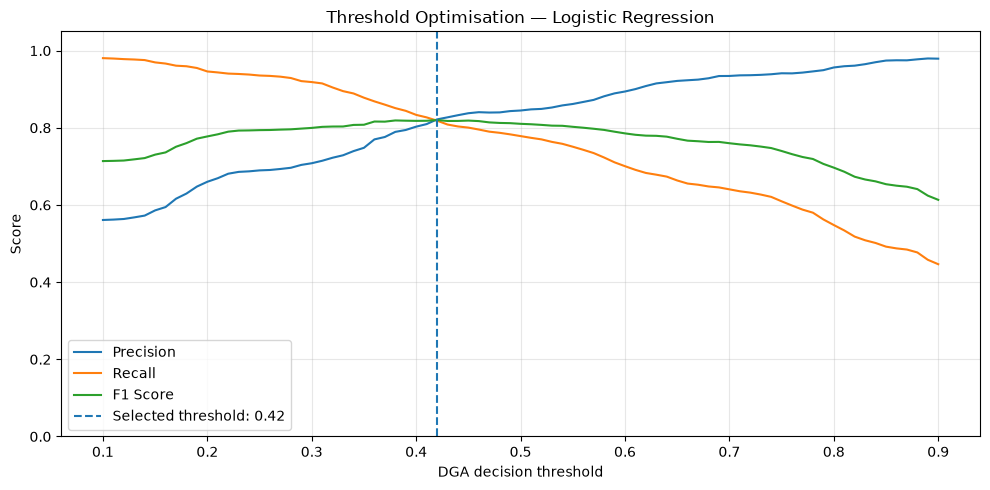

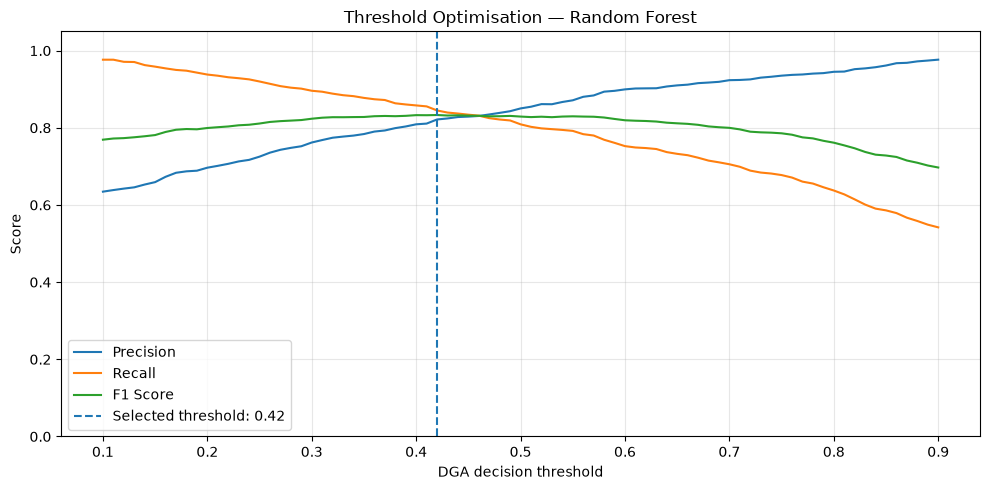

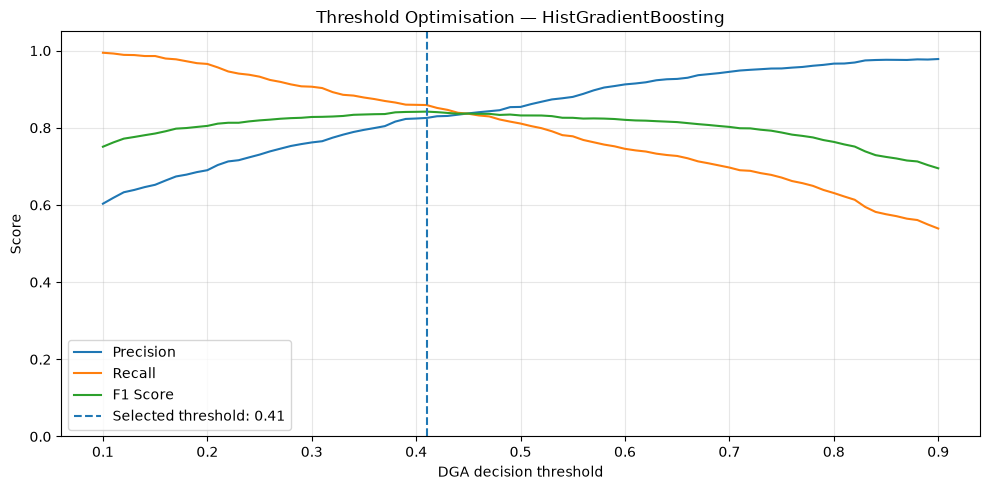

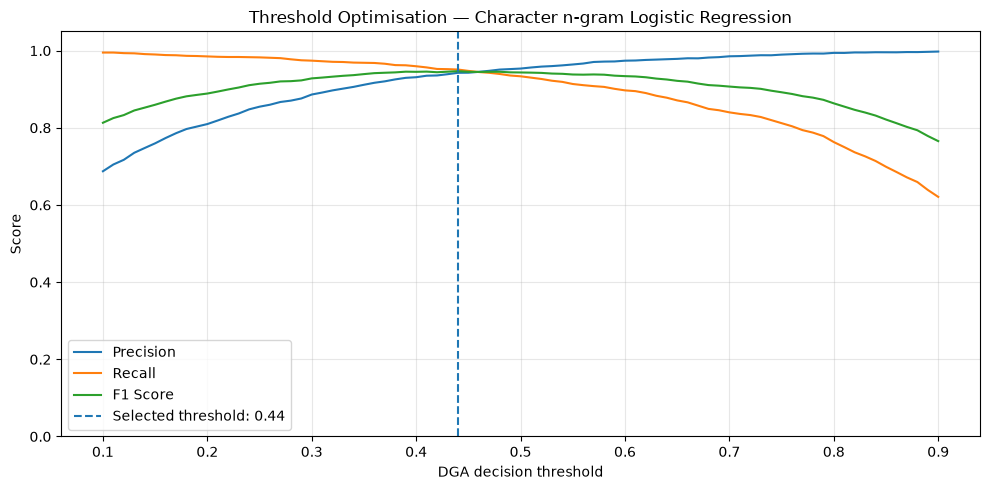

In [15]:
# Plot precision, recall and F1 across thresholds for each model.
for model_name, results_for_model in threshold_results.items():
    # Sort by threshold for a correctly ordered line plot.
    plot_data = results_for_model.sort_values("threshold")
    selected_threshold = recommended_thresholds[model_name]

    plt.figure(figsize=(10, 5))
    plt.plot(
        plot_data["threshold"],
        plot_data["precision"],
        label="Precision"
    )
    plt.plot(
        plot_data["threshold"],
        plot_data["recall"],
        label="Recall"
    )
    plt.plot(
        plot_data["threshold"],
        plot_data["f1"],
        label="F1 Score"
    )
    plt.axvline(
        selected_threshold,
        linestyle="--",
        label=f"Selected threshold: {selected_threshold:.2f}"
    )

    plt.title(f"Threshold Optimisation — {model_name}")
    plt.xlabel("DGA decision threshold")
    plt.ylabel("Score")
    plt.ylim(0, 1.05)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

## 11. Final evaluation on the untouched test set

Apply each model's threshold selected on the validation set. These test results are the final held-out evaluation; do not use them to go back and select another threshold.

Final held-out test performance at validation-selected thresholds:


,threshold,accuracy,precision,recall,f1,specificity,false_positive_rate,false_negative_rate,true_negatives,false_positives,false_negatives,true_positives,roc_auc,average_precision
Model,,,,,,,,,,,,,,
Logistic Regression,0.42,0.8120,0.8114,0.8130,0.8122,0.8110,0.1890,0.1870,1622,378,374,1626,0.8917,0.9073
Random Forest,0.42,0.8285,0.8165,0.8475,0.8317,0.8095,0.1905,0.1525,1619,381,305,1695,0.9170,0.9260
HistGradientBoosting,0.41,0.8292,0.8113,0.8580,0.8340,0.8005,0.1995,0.1420,1601,399,284,1716,0.9232,0.9318
Character n-gram Logistic Regression,0.44,0.9430,0.9426,0.9435,0.9430,0.9425,0.0575,0.0565,1885,115,113,1887,0.9845,0.9846


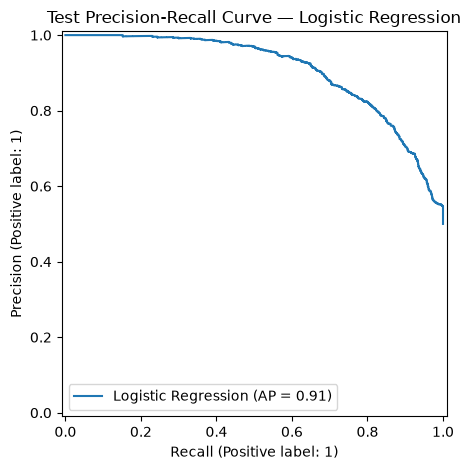

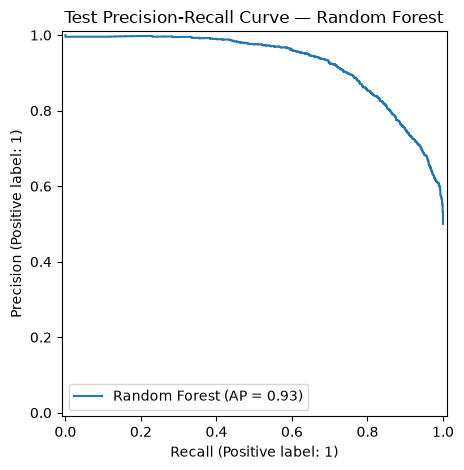

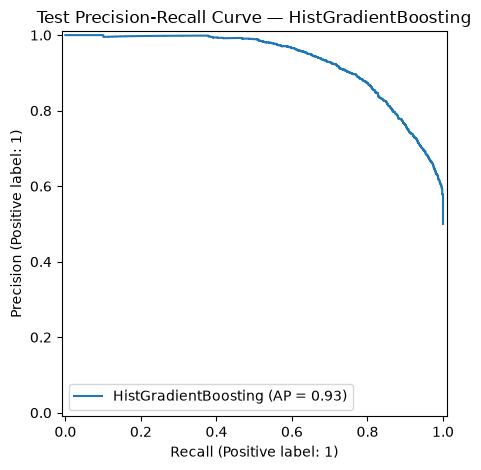

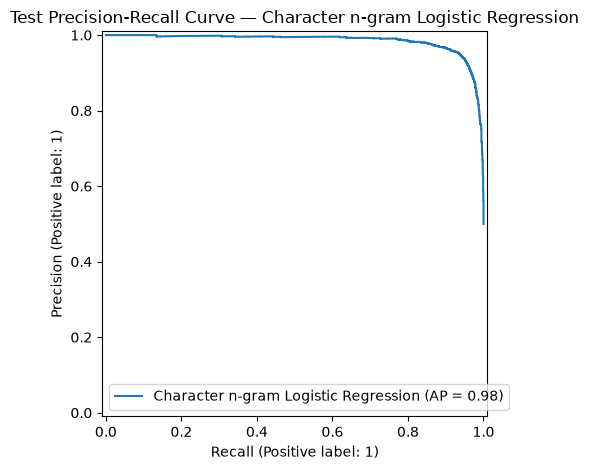

In [16]:
# Test probabilities for all four models.
test_probabilities = {
    name: model.predict_proba(X_test)[:, 1]
    for name, model in best_models.items()
}
test_probabilities[
    "Character n-gram Logistic Regression"
] = ngram_test_prob

final_test_rows = []
final_test_predictions = {}

for model_name, probabilities in test_probabilities.items():
    selected_threshold = recommended_thresholds[model_name]
    predictions = (probabilities >= selected_threshold).astype(int)
    final_test_predictions[model_name] = predictions

    metrics = binary_metrics_at_threshold(
        y_test,
        probabilities,
        selected_threshold
    )

    metrics["roc_auc"] = roc_auc_score(y_test, probabilities)
    metrics["average_precision"] = average_precision_score(
        y_test, probabilities
    )

    final_test_rows.append({
        "Model": model_name,
        **metrics
    })

final_test_results = pd.DataFrame(final_test_rows).set_index("Model")

print("Final held-out test performance at validation-selected thresholds:")
display(final_test_results.round(4))

# Precision-recall curves are shown on the test set for descriptive final evaluation.
for model_name, probabilities in test_probabilities.items():
    PrecisionRecallDisplay.from_predictions(
        y_test,
        probabilities,
        name=model_name
    )
    plt.title(f"Test Precision-Recall Curve — {model_name}")
    plt.tight_layout()
    plt.show()

\n========== Logistic Regression ==========
              precision    recall  f1-score   support

      Benign       0.81      0.81      0.81      2000
         DGA       0.81      0.81      0.81      2000

    accuracy                           0.81      4000
   macro avg       0.81      0.81      0.81      4000
weighted avg       0.81      0.81      0.81      4000



,Predicted Benign,Predicted DGA
Actual Benign,1622,378
Actual DGA,374,1626


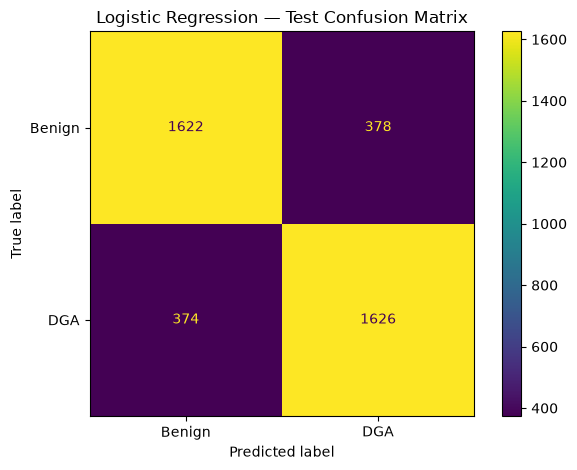

\n========== Random Forest ==========
              precision    recall  f1-score   support

      Benign       0.84      0.81      0.83      2000
         DGA       0.82      0.85      0.83      2000

    accuracy                           0.83      4000
   macro avg       0.83      0.83      0.83      4000
weighted avg       0.83      0.83      0.83      4000



,Predicted Benign,Predicted DGA
Actual Benign,1619,381
Actual DGA,305,1695


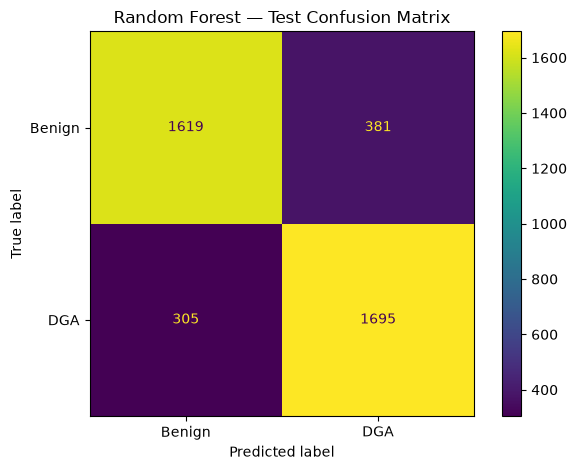

\n========== HistGradientBoosting ==========
              precision    recall  f1-score   support

      Benign       0.85      0.80      0.82      2000
         DGA       0.81      0.86      0.83      2000

    accuracy                           0.83      4000
   macro avg       0.83      0.83      0.83      4000
weighted avg       0.83      0.83      0.83      4000



,Predicted Benign,Predicted DGA
Actual Benign,1601,399
Actual DGA,284,1716


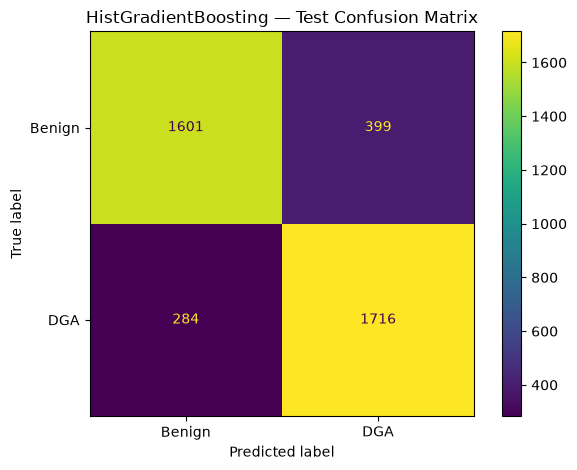

\n========== Character n-gram Logistic Regression ==========
              precision    recall  f1-score   support

      Benign       0.94      0.94      0.94      2000
         DGA       0.94      0.94      0.94      2000

    accuracy                           0.94      4000
   macro avg       0.94      0.94      0.94      4000
weighted avg       0.94      0.94      0.94      4000



,Predicted Benign,Predicted DGA
Actual Benign,1885,115
Actual DGA,113,1887


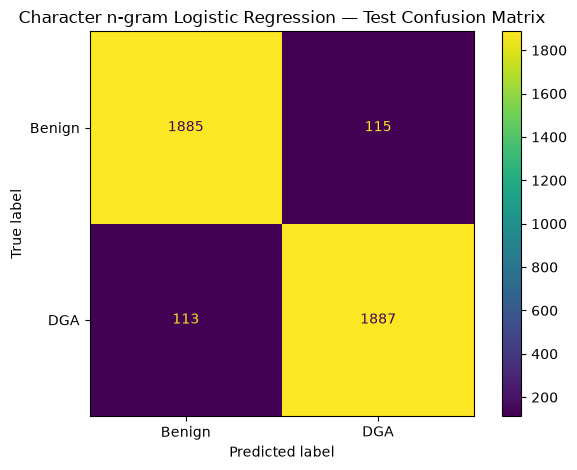

In [17]:
## Test-set classification reports and confusion matrices

for model_name, predictions in final_test_predictions.items():
    print(f"\\n========== {model_name} ==========")
    print(
        classification_report(
            y_test,
            predictions,
            labels=[0, 1],
            target_names=["Benign", "DGA"],
            zero_division=0
        )
    )

    cm = confusion_matrix(y_test, predictions, labels=[0, 1])
    display(pd.DataFrame(
        cm,
        index=["Actual Benign", "Actual DGA"],
        columns=["Predicted Benign", "Predicted DGA"]
    ))

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Benign", "DGA"]
    ).plot()
    plt.title(f"{model_name} — Test Confusion Matrix")
    plt.tight_layout()
    plt.show()

,Validation ROC AUC,Validation Average Precision
Model,,
Logistic Regression,0.9002,0.9138
Random Forest,0.9164,0.9257
HistGradientBoosting,0.9271,0.9346
Character n-gram Logistic Regression,0.9857,0.9869


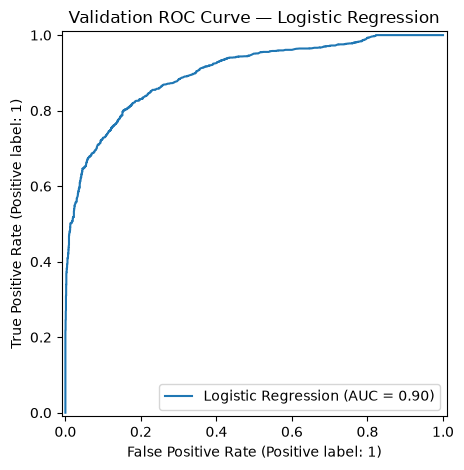

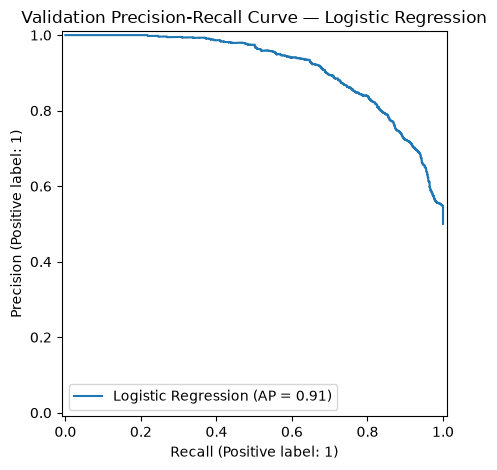

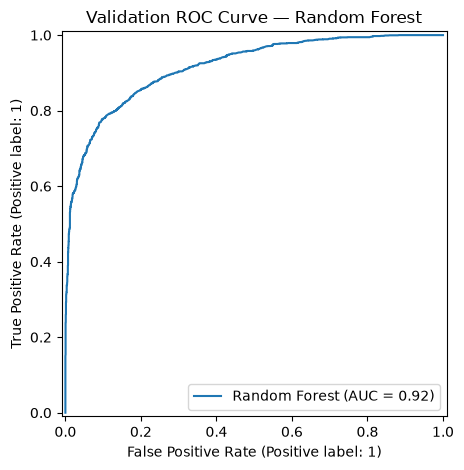

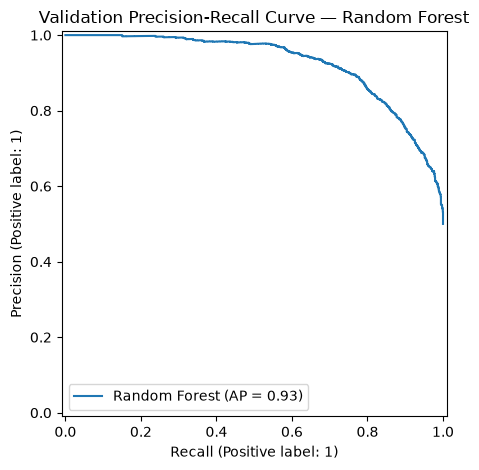

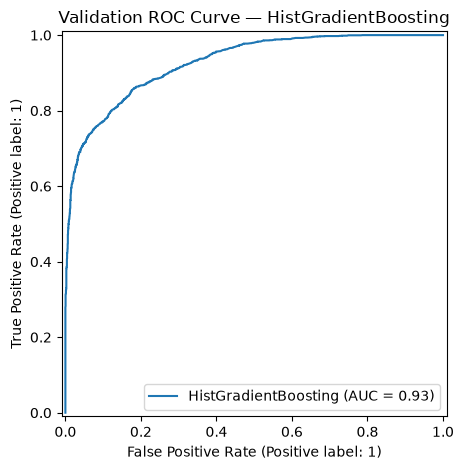

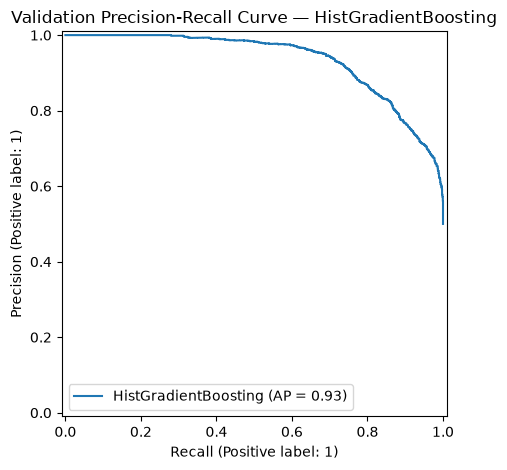

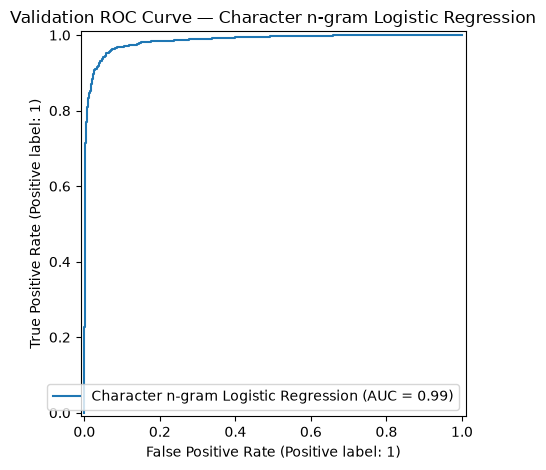

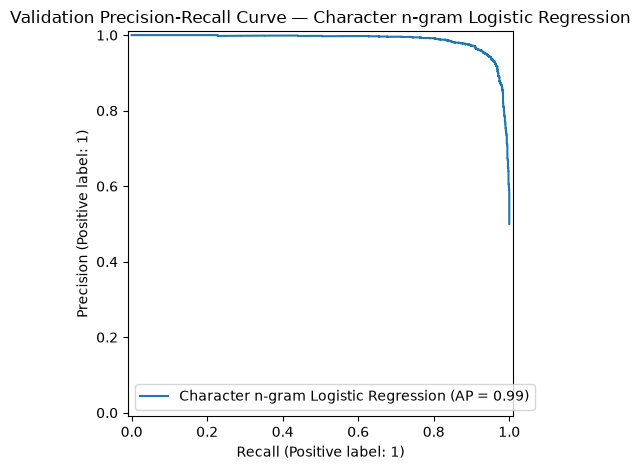

In [18]:
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay

validation_ranking_rows = []

for model_name, probabilities in validation_probabilities.items():
    validation_ranking_rows.append({
        "Model": model_name,
        "Validation ROC AUC": roc_auc_score(y_val, probabilities),
        "Validation Average Precision": average_precision_score(y_val, probabilities)
    })

validation_ranking_results = (
    pd.DataFrame(validation_ranking_rows).set_index("Model")
)
display(validation_ranking_results.round(4))

for model_name, probabilities in validation_probabilities.items():
    RocCurveDisplay.from_predictions(y_val, probabilities, name=model_name)
    plt.title(f"Validation ROC Curve — {model_name}")
    plt.tight_layout()
    plt.show()

    PrecisionRecallDisplay.from_predictions(y_val, probabilities, name=model_name)
    plt.title(f"Validation Precision-Recall Curve — {model_name}")
    plt.tight_layout()
    plt.show()


Permutation importance: Logistic Regression


,feature,importance_mean,importance_std
0,max_consonant_sequence,0.30893,0.00353
1,digit_count,0.21343,0.00428
2,digit_ratio,0.11209,0.00245
3,domain_length,0.04732,0.00220
4,hyphen_count,0.02065,0.00169
5,consonant_count,0.01363,0.00160
6,unique_char_ratio,0.00700,0.00094
7,vowel_count,0.00506,0.00066
8,entropy,0.00089,0.00067
9,vowel_ratio,0.00030,0.00023


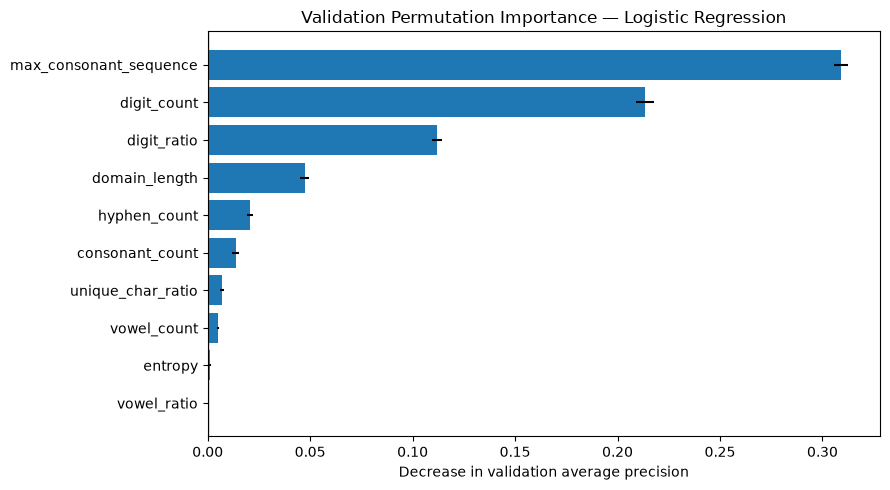

Permutation importance: Random Forest


,feature,importance_mean,importance_std
0,max_consonant_sequence,0.19043,0.00466
1,vowel_ratio,0.02074,0.00190
2,hyphen_count,0.01134,0.00091
3,digit_count,0.00783,0.00114
4,domain_length,0.00596,0.00143
5,digit_ratio,0.00543,0.00102
6,entropy,0.00522,0.00179
7,consonant_count,0.00502,0.00097
8,vowel_count,-0.00032,0.00083
9,unique_char_ratio,-0.00032,0.00065


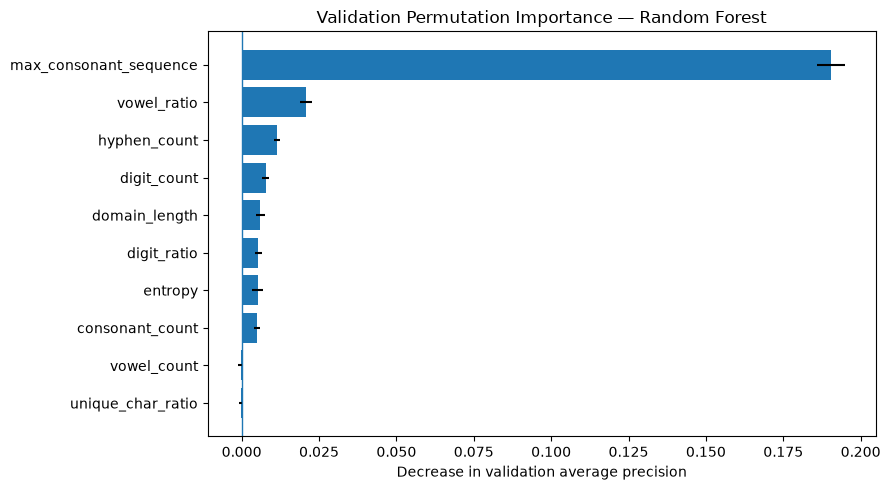

Permutation importance: HistGradientBoosting


,feature,importance_mean,importance_std
0,max_consonant_sequence,0.23243,0.00399
1,digit_count,0.07022,0.00272
2,vowel_ratio,0.02450,0.00231
3,hyphen_count,0.01712,0.00104
4,entropy,0.01180,0.00123
5,domain_length,0.01079,0.00114
6,digit_ratio,0.00457,0.00063
7,unique_char_ratio,0.00321,0.00080
8,vowel_count,0.00287,0.00072
9,consonant_count,0.00219,0.00053


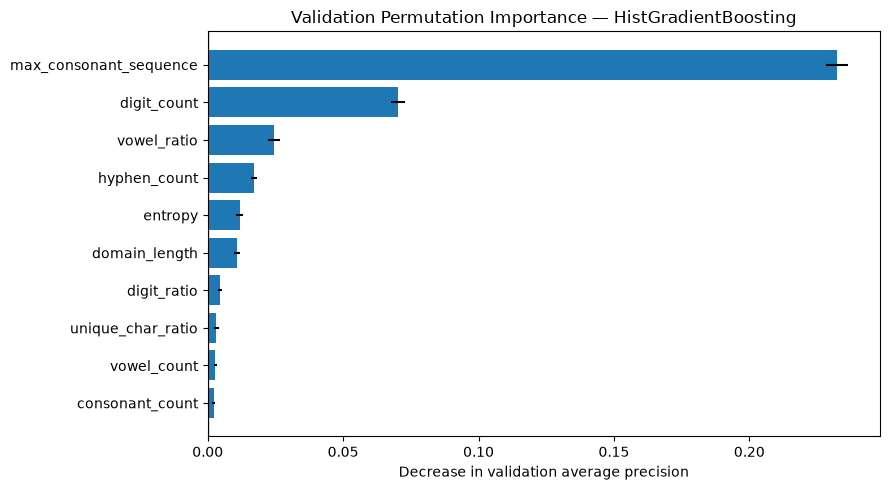

In [19]:
from sklearn.inspection import permutation_importance

numeric_permutation_importance = {}

for model_name, fitted_model in best_models.items():
    print(f"Permutation importance: {model_name}")
    perm = permutation_importance(
        fitted_model,
        X_val,
        y_val,
        scoring="average_precision",
        n_repeats=8,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )

    importance_df = pd.DataFrame({
        "feature": FEATURE_COLUMNS,
        "importance_mean": perm.importances_mean,
        "importance_std": perm.importances_std
    }).sort_values("importance_mean", ascending=False).reset_index(drop=True)

    numeric_permutation_importance[model_name] = importance_df
    display(importance_df.round(5))

    plot_df = importance_df.sort_values("importance_mean")
    plt.figure(figsize=(9, 5))
    plt.barh(plot_df["feature"], plot_df["importance_mean"],
             xerr=plot_df["importance_std"])
    plt.axvline(0, linewidth=1)
    plt.title(f"Validation Permutation Importance — {model_name}")
    plt.xlabel("Decrease in validation average precision")
    plt.tight_layout()
    plt.show()


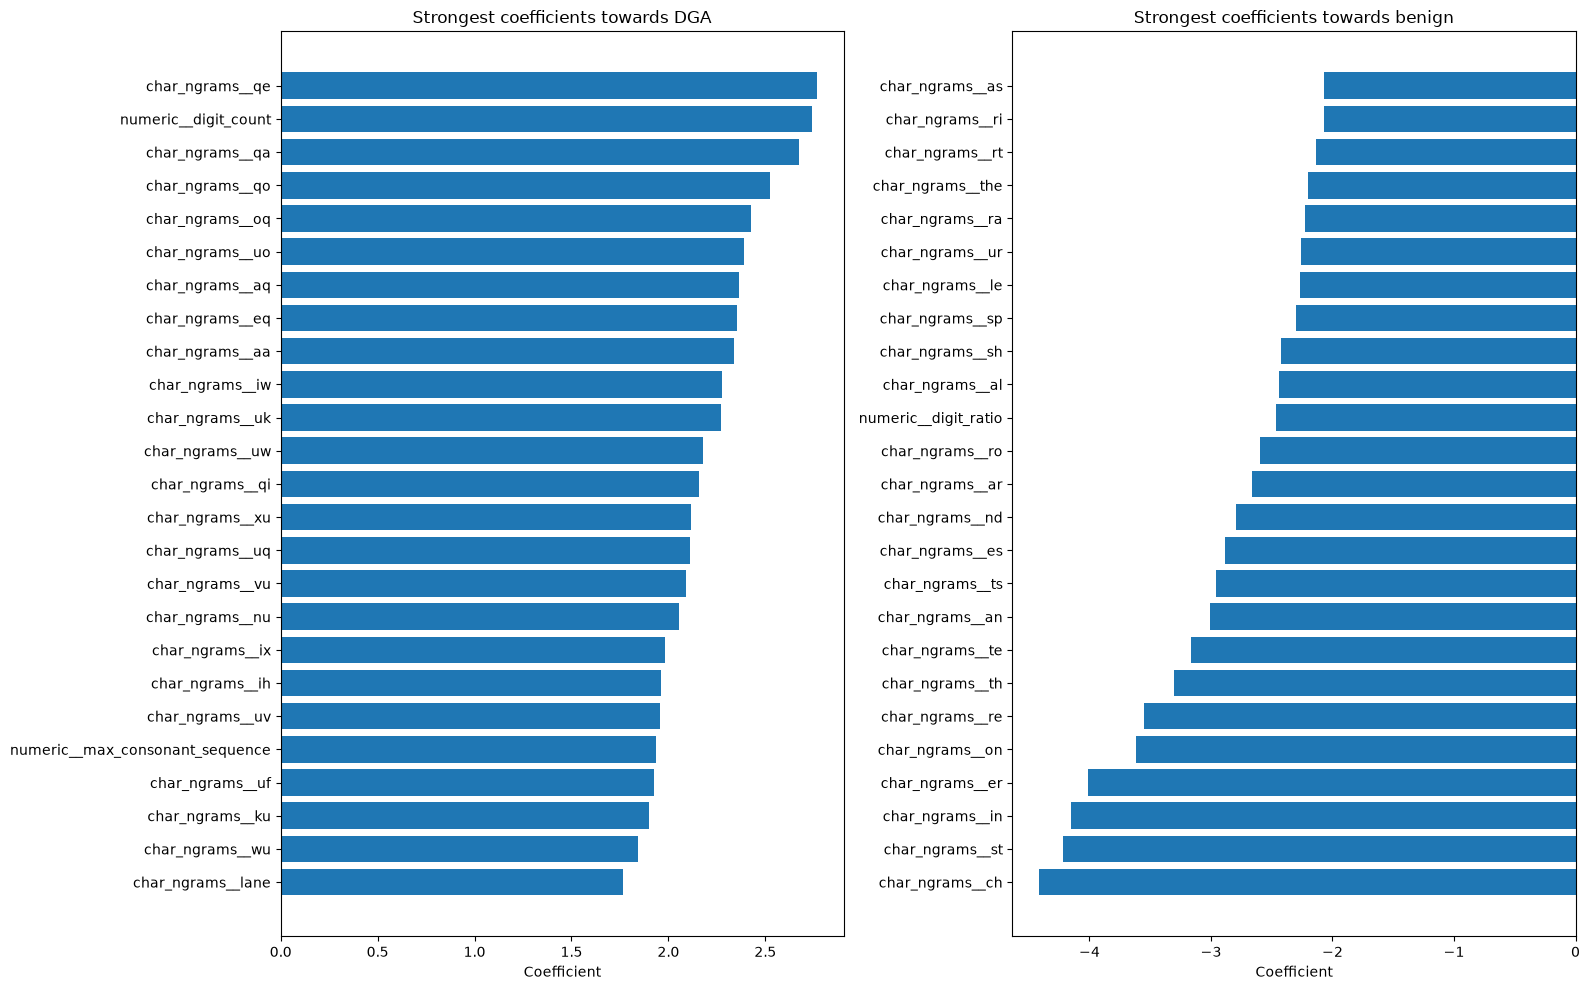

Largest positive weights:


,feature,coefficient
24722,char_ngrams__qe,2.766306
35736,numeric__digit_count,2.742492
24581,char_ngrams__qa,2.674272
25092,char_ngrams__qo,2.522380
22850,char_ngrams__oq,2.426003
30742,char_ngrams__uo,2.390343
4178,char_ngrams__aq,2.363965
9874,char_ngrams__eq,2.356100
2810,char_ngrams__aa,2.336837
15478,char_ngrams__iw,2.277986


Largest negative weights:


,feature,coefficient
6410,char_ngrams__ch,-4.412877
28209,char_ngrams__st,-4.217405
14722,char_ngrams__in,-4.153835
9921,char_ngrams__er,-4.008071
22562,char_ngrams__on,-3.616483
25830,char_ngrams__re,-3.548063
29029,char_ngrams__th,-3.300667
28844,char_ngrams__te,-3.162544
3871,char_ngrams__an,-3.009997
29579,char_ngrams__ts,-2.959181


In [20]:
ngram_transformer = ngram_model.named_steps["features"]
ngram_classifier = ngram_model.named_steps["classifier"]

ngram_feature_names = ngram_transformer.get_feature_names_out()
ngram_coefficients = ngram_classifier.coef_[0]

ngram_coefficient_table = pd.DataFrame({
    "feature": ngram_feature_names,
    "coefficient": ngram_coefficients
})

top_dga_coefficients = (
    ngram_coefficient_table.nlargest(25, "coefficient")
    .sort_values("coefficient")
)
top_benign_coefficients = (
    ngram_coefficient_table.nsmallest(25, "coefficient")
    .sort_values("coefficient")
)

fig, axes = plt.subplots(1, 2, figsize=(16, 10))
axes[0].barh(top_dga_coefficients["feature"],
             top_dga_coefficients["coefficient"])
axes[0].set_title("Strongest coefficients towards DGA")
axes[0].set_xlabel("Coefficient")
axes[1].barh(top_benign_coefficients["feature"],
             top_benign_coefficients["coefficient"])
axes[1].set_title("Strongest coefficients towards benign")
axes[1].set_xlabel("Coefficient")
plt.tight_layout()
plt.show()

ngram_top_coefficients = pd.concat([
    ngram_coefficient_table.nlargest(100, "coefficient"),
    ngram_coefficient_table.nsmallest(100, "coefficient")
]).drop_duplicates("feature").reset_index(drop=True)

print("Largest positive weights:")
display(ngram_coefficient_table.nlargest(25, "coefficient"))
print("Largest negative weights:")
display(ngram_coefficient_table.nsmallest(25, "coefficient"))


In [21]:
def explain_domain(domain, model_name, top_n=15):
    domain = str(domain).lower().strip()
    if not domain:
        raise ValueError("Domain must not be empty.")

    numeric_features = extract_domain_features(domain)
    numeric_row = pd.DataFrame([numeric_features], columns=FEATURE_COLUMNS)
    mixed_row = pd.DataFrame([{"domain": domain, **numeric_features}])

    if model_name == "Character n-gram Logistic Regression":
        fitted_model = ngram_model
        probability = float(fitted_model.predict_proba(mixed_row)[0, 1])
        threshold = float(recommended_thresholds[model_name])

        transformed = fitted_model.named_steps["features"].transform(mixed_row)
        coef = fitted_model.named_steps["classifier"].coef_[0]
        names = fitted_model.named_steps["features"].get_feature_names_out()
        values = transformed.toarray()[0] if hasattr(transformed, "toarray") else np.asarray(transformed)[0]
        signed = values * coef

        explanation = pd.DataFrame({
            "feature": names,
            "transformed_value": values,
            "signed_contribution_to_DGA_score": signed
        })
        explanation = explanation[explanation["transformed_value"] != 0].copy()
        explanation["direction"] = np.where(
            explanation["signed_contribution_to_DGA_score"] >= 0,
            "towards DGA", "towards benign"
        )
        explanation["absolute_contribution"] = (
            explanation["signed_contribution_to_DGA_score"].abs()
        )
        explanation = explanation.nlargest(top_n, "absolute_contribution")
        method = "Active transformed feature values multiplied by fitted coefficients"

    elif model_name in best_models:
        fitted_model = best_models[model_name]
        probability = float(fitted_model.predict_proba(numeric_row)[0, 1])
        threshold = float(recommended_thresholds[model_name])
        train_medians = X_train.median(numeric_only=True)

        rows = []
        for feature in FEATURE_COLUMNS:
            changed = numeric_row.copy()
            changed.loc[0, feature] = train_medians[feature]
            changed_probability = float(fitted_model.predict_proba(changed)[0, 1])
            rows.append({
                "feature": feature,
                "observed_value": float(numeric_row.loc[0, feature]),
                "training_median": float(train_medians[feature]),
                "probability_after_replacement": changed_probability,
                "probability_change": changed_probability - probability,
                "absolute_probability_change": abs(changed_probability - probability)
            })
        explanation = pd.DataFrame(rows).nlargest(
            top_n, "absolute_probability_change"
        )
        method = "One-feature-at-a-time replacement with training median; non-additive sensitivity analysis"
    else:
        raise ValueError(
            "Choose one of: " + ", ".join(list(best_models) +
            ["Character n-gram Logistic Regression"])
        )

    result = {
        "domain": domain,
        "model": model_name,
        "dga_probability": probability,
        "threshold": threshold,
        "prediction": "DGA" if probability >= threshold else "Benign",
        "method": method,
        "lexical_features": numeric_features,
        "explanation": explanation.reset_index(drop=True)
    }

    print("Domain:", result["domain"])
    print("Model:", result["model"])
    print(f"DGA probability: {probability:.4f}")
    print(f"Decision threshold: {threshold:.4f}")
    print("Prediction:", result["prediction"])
    print("Method:", method)
    print("\nExtracted lexical features:")
    display(pd.DataFrame([numeric_features]))
    print("\nMost influential features:")
    display(result["explanation"])
    return result


# Change the example domain/model to inspect a different prediction.
example_domain_explanation = explain_domain(
    "xj3kq9m2zv-example.com",
    "Character n-gram Logistic Regression"
)


Domain: xj3kq9m2zv-example.com
Model: Character n-gram Logistic Regression
DGA probability: 0.0749
Decision threshold: 0.4400
Prediction: Benign
Method: Active transformed feature values multiplied by fitted coefficients

Extracted lexical features:


,domain_length,digit_count,vowel_count,consonant_count,digit_ratio,vowel_ratio,unique_char_ratio,entropy,hyphen_count,max_consonant_sequence
0,22,3,4,13,0.136364,0.181818,0.818182,4.061482,1,3



Most influential features:


,feature,transformed_value,signed_contribution_to_DGA_score,direction,absolute_contribution
0,numeric__hyphen_count,3.092334,-5.236934,towards benign,5.236934
1,numeric__digit_count,0.993813,2.725526,towards DGA,2.725526
2,numeric__digit_ratio,0.388727,-0.959336,towards benign,0.959336
3,numeric__entropy,1.933983,0.934686,towards DGA,0.934686
4,numeric__domain_length,1.441472,0.783787,towards DGA,0.783787
5,numeric__max_consonant_sequence,-0.340146,-0.658560,towards benign,0.658560
6,numeric__consonant_count,1.043569,-0.486404,towards benign,0.486404
7,char_ngrams__xa,0.145625,0.234372,towards DGA,0.234372
8,char_ngrams__le,0.101128,-0.229064,towards benign,0.229064
9,char_ngrams__mp,0.134641,-0.166757,towards benign,0.166757


In [22]:
test_prediction_frame = pd.DataFrame(
    final_test_predictions,
    index=y_test.index
)
test_prediction_frame["actual"] = y_test

model_columns = list(final_test_predictions.keys())
test_prediction_frame["disagreement_count"] = (
    test_prediction_frame[model_columns].nunique(axis=1) - 1
)
test_prediction_frame["model_vote_count_DGA"] = (
    test_prediction_frame[model_columns].sum(axis=1)
)
test_prediction_frame["unanimous_prediction"] = np.where(
    test_prediction_frame["model_vote_count_DGA"] == len(model_columns),
    "DGA",
    np.where(test_prediction_frame["model_vote_count_DGA"] == 0,
             "Benign", "Disagreement")
)

print("Agreement summary:")
display(test_prediction_frame["unanimous_prediction"].value_counts().to_frame("domains"))

disagreement_indices = test_prediction_frame.index[
    test_prediction_frame["unanimous_prediction"] == "Disagreement"
]
disagreement_domains = sample.loc[
    disagreement_indices, ["domain", "threat"] + FEATURE_COLUMNS
].copy()
for model_name in model_columns:
    disagreement_domains[model_name] = test_prediction_frame.loc[
        disagreement_indices, model_name
    ]
display(disagreement_domains.head(100))


Agreement summary:


,domains
unanimous_prediction,
DGA,1623
Benign,1456
Disagreement,921


,domain,threat,domain_length,digit_count,vowel_count,consonant_count,digit_ratio,vowel_ratio,unique_char_ratio,entropy,hyphen_count,max_consonant_sequence,Logistic Regression,Random Forest,HistGradientBoosting,Character n-gram Logistic Regression
8026,diamondsinstyle,benign,15,0,5,10,0.0,0.333333,0.733333,3.373557,0,5,1,1,1,0
2514,eiegmwamq,dga,9,0,4,5,0.0,0.444444,0.777778,2.725481,0,3,0,0,1,1
14514,iquqdn,dga,6,0,2,4,0.0,0.333333,0.833333,2.251629,0,3,0,0,1,1
7857,nafecufyrunoraribirasy,dga,22,0,9,13,0.0,0.409091,0.545455,3.425119,0,3,0,1,1,1
8899,dobrzezaprojektowane,benign,20,0,8,12,0.0,0.400000,0.650000,3.546439,0,3,0,0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
741,vyh,benign,3,0,0,3,0.0,0.000000,1.000000,1.584963,0,3,1,0,0,1
6455,bidcpkelutlo,dga,12,0,4,8,0.0,0.333333,0.916667,3.418296,0,4,1,0,1,1
3649,mmtbellefrictionlessv,dga,21,0,6,15,0.0,0.285714,0.619048,3.558519,0,4,1,0,0,1
6188,twxukmj,dga,7,0,1,6,0.0,0.142857,1.000000,2.807355,0,3,0,1,1,1


In [23]:
test_domain_frame = sample.loc[
    y_test.index, ["domain", "threat"] + FEATURE_COLUMNS
].copy()

false_positive_examples = {}
false_negative_examples = {}

for model_name, predictions in final_test_predictions.items():
    fp_mask = (y_test.to_numpy() == 0) & (predictions == 1)
    fn_mask = (y_test.to_numpy() == 1) & (predictions == 0)

    fp = test_domain_frame.loc[fp_mask].copy()
    fn = test_domain_frame.loc[fn_mask].copy()

    false_positive_examples[model_name] = fp
    false_negative_examples[model_name] = fn

    print(f"\n{model_name}: false positives = {len(fp)}, false negatives = {len(fn)}")
    print("False-positive examples:")
    display(fp.head(25))
    print("False-negative examples:")
    display(fn.head(25))



Logistic Regression: false positives = 378, false negatives = 374
False-positive examples:


,domain,threat,domain_length,digit_count,vowel_count,consonant_count,digit_ratio,vowel_ratio,unique_char_ratio,entropy,hyphen_count,max_consonant_sequence
8026,diamondsinstyle,benign,15,0,5,10,0.000000,0.333333,0.733333,3.373557,0,5
2965,americandefenseenterprises,benign,26,0,11,15,0.000000,0.423077,0.461538,3.242126,0,3
19537,onyxcollective,benign,14,0,5,9,0.000000,0.357143,0.714286,3.235926,0,4
18411,partyskirts,benign,11,0,2,9,0.000000,0.181818,0.727273,2.913977,0,5
8358,greentechlocksmith,benign,18,0,5,13,0.000000,0.277778,0.722222,3.572431,0,4
13822,polyctenidae,benign,12,0,5,7,0.000000,0.416667,0.916667,3.418296,0,4
1644,1stflowersandgifts,benign,18,1,4,13,0.055556,0.222222,0.777778,3.683542,0,4
14258,northlandsecurity,benign,17,0,5,12,0.000000,0.294118,0.823529,3.734522,0,4
15033,northcollegehill,benign,16,0,5,11,0.000000,0.312500,0.625000,3.125000,0,4
1933,311libertylaw,benign,13,3,3,7,0.230769,0.230769,0.846154,3.392747,0,4


False-negative examples:


,domain,threat,domain_length,digit_count,vowel_count,consonant_count,digit_ratio,vowel_ratio,unique_char_ratio,entropy,hyphen_count,max_consonant_sequence
2514,eiegmwamq,dga,9,0,4,5,0.0,0.444444,0.777778,2.725481,0,3
14514,iquqdn,dga,6,0,2,4,0.0,0.333333,0.833333,2.251629,0,3
7857,nafecufyrunoraribirasy,dga,22,0,9,13,0.0,0.409091,0.545455,3.425119,0,3
11356,mempsign,dga,8,0,2,6,0.0,0.250000,0.875000,2.750000,0,3
9108,xuxozaxotupuwikaxo,dga,18,0,9,9,0.0,0.500000,0.555556,3.086049,0,1
14509,digafywetyre,dga,12,0,4,8,0.0,0.333333,0.833333,3.251629,0,3
12172,fogevybe,dga,8,0,3,5,0.0,0.375000,0.875000,2.750000,0,3
5295,wwfaolice,dga,9,0,4,5,0.0,0.444444,0.888889,2.947703,0,3
18736,iqggecius,dga,9,0,4,5,0.0,0.444444,0.777778,2.725481,0,3
11496,qexunupija,dga,10,0,5,5,0.0,0.500000,0.900000,3.121928,0,1



Random Forest: false positives = 381, false negatives = 305
False-positive examples:


,domain,threat,domain_length,digit_count,vowel_count,consonant_count,digit_ratio,vowel_ratio,unique_char_ratio,entropy,hyphen_count,max_consonant_sequence
8026,diamondsinstyle,benign,15,0,5,10,0.000000,0.333333,0.733333,3.373557,0,5
18411,partyskirts,benign,11,0,2,9,0.000000,0.181818,0.727273,2.913977,0,5
5553,untinct,benign,7,0,2,5,0.000000,0.285714,0.714286,2.235926,0,3
14763,enjoybhutan,benign,11,0,4,7,0.000000,0.363636,0.909091,3.277613,0,3
13822,polyctenidae,benign,12,0,5,7,0.000000,0.416667,0.916667,3.418296,0,4
1644,1stflowersandgifts,benign,18,1,4,13,0.055556,0.222222,0.777778,3.683542,0,4
14258,northlandsecurity,benign,17,0,5,12,0.000000,0.294118,0.823529,3.734522,0,4
1933,311libertylaw,benign,13,3,3,7,0.230769,0.230769,0.846154,3.392747,0,4
9525,cellsmr,benign,7,0,1,6,0.000000,0.142857,0.857143,2.521641,0,5
5333,papolebuildingconstruction,benign,26,0,10,16,0.000000,0.384615,0.576923,3.767183,0,4


... (6 outputs left out)


Character n-gram Logistic Regression: false positives = 115, false negatives = 113
False-positive examples:


,domain,threat,domain_length,digit_count,vowel_count,consonant_count,digit_ratio,vowel_ratio,unique_char_ratio,entropy,hyphen_count,max_consonant_sequence
8899,dobrzezaprojektowane,benign,20,0,8,12,0.000000,0.400000,0.650000,3.546439,0,3
17397,lucykeyboard,benign,12,0,4,8,0.000000,0.333333,0.916667,3.418296,0,3
14763,enjoybhutan,benign,11,0,4,7,0.000000,0.363636,0.909091,3.277613,0,3
1933,311libertylaw,benign,13,3,3,7,0.230769,0.230769,0.846154,3.392747,0,4
9525,cellsmr,benign,7,0,1,6,0.000000,0.142857,0.857143,2.521641,0,5
18811,wellthychoices,benign,14,0,4,10,0.000000,0.285714,0.714286,3.235926,0,7
2081,pflegeagentur24,benign,15,2,5,8,0.133333,0.333333,0.800000,3.456565,0,3
4681,fbckilgore,benign,10,0,3,7,0.000000,0.300000,1.000000,3.321928,0,4
4917,cmcfcu,benign,6,0,1,5,0.000000,0.166667,0.666667,1.792481,0,5
14532,bftrk,benign,5,0,0,5,0.000000,0.000000,1.000000,2.321928,0,5


False-negative examples:


,domain,threat,domain_length,digit_count,vowel_count,consonant_count,digit_ratio,vowel_ratio,unique_char_ratio,entropy,hyphen_count,max_consonant_sequence
11356,mempsign,dga,8,0,2,6,0.0,0.250000,0.875000,2.750000,0,3
12620,ygeivvew,dga,8,0,3,5,0.0,0.375000,0.750000,2.500000,0,2
3933,ixooakiscov,dga,11,0,6,5,0.0,0.545455,0.727273,2.845351,0,2
4843,nomadafifato,dga,12,0,6,6,0.0,0.500000,0.666667,2.855389,0,1
3022,zxraland,dga,8,0,2,6,0.0,0.250000,0.875000,2.750000,0,3
3790,uranyuatugbbu,dga,13,0,6,7,0.0,0.461538,0.615385,2.777363,0,3
14249,yeirdoagx,dga,9,0,4,5,0.0,0.444444,1.000000,3.169925,0,2
15833,nfewinglane,dga,11,0,4,7,0.0,0.363636,0.727273,2.845351,0,3
8718,tucebugo,dga,8,0,4,4,0.0,0.500000,0.875000,2.750000,0,1
1387,hmgurhonkk,dga,10,0,2,8,0.0,0.200000,0.800000,2.921928,0,3


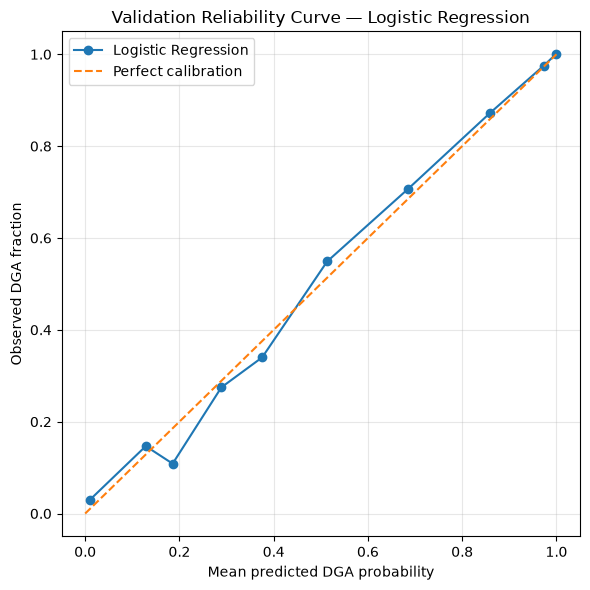

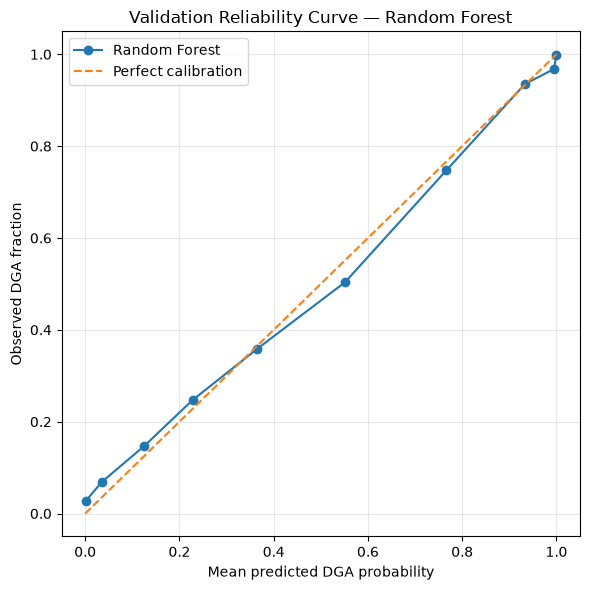

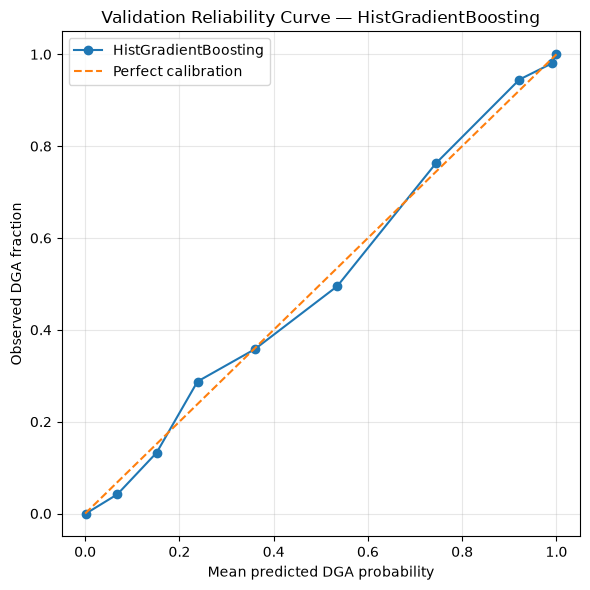

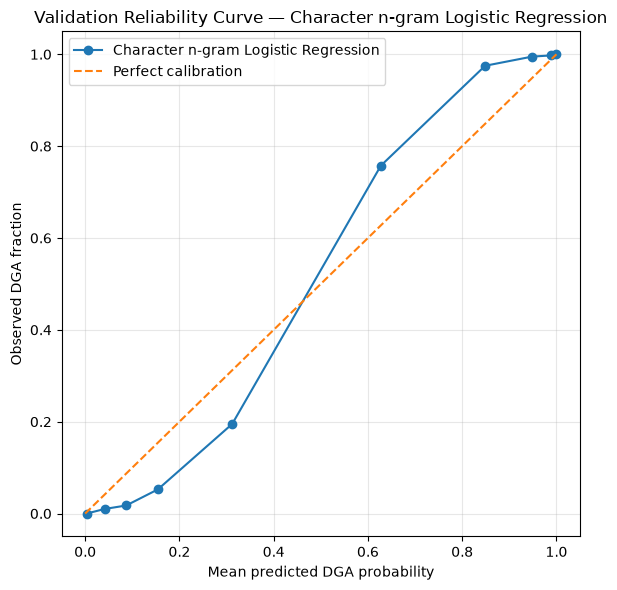

Lower Brier scores indicate better probabilistic accuracy:


,Validation Brier Score
Model,
Logistic Regression,0.12616
Random Forest,0.11571
HistGradientBoosting,0.10855
Character n-gram Logistic Regression,0.04880


In [24]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

calibration_rows = []

for model_name, probabilities in validation_probabilities.items():
    brier = brier_score_loss(y_val, probabilities)
    calibration_rows.append({
        "Model": model_name,
        "Validation Brier Score": brier
    })

    fraction_positive, mean_predicted = calibration_curve(
        y_val, probabilities, n_bins=10, strategy="quantile"
    )
    plt.figure(figsize=(6, 6))
    plt.plot(mean_predicted, fraction_positive, marker="o", label=model_name)
    plt.plot([0, 1], [0, 1], linestyle="--", label="Perfect calibration")
    plt.xlabel("Mean predicted DGA probability")
    plt.ylabel("Observed DGA fraction")
    plt.title(f"Validation Reliability Curve — {model_name}")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

calibration_results = pd.DataFrame(calibration_rows).set_index("Model")
print("Lower Brier scores indicate better probabilistic accuracy:")
display(calibration_results.round(5))


In [25]:
# Reconfirm exact-domain separation across the existing partitions.
train_domain_series = sample.iloc[train_idx]["domain"].astype(str)
val_domain_series = sample.iloc[val_idx]["domain"].astype(str)
test_domain_series = sample.iloc[test_idx]["domain"].astype(str)

assert set(train_domain_series).isdisjoint(set(val_domain_series))
assert set(train_domain_series).isdisjoint(set(test_domain_series))
assert set(val_domain_series).isdisjoint(set(test_domain_series))
assert not sample["domain"].duplicated().any()

print("Exact duplicate and split-overlap checks: passed.")

# Bounded approximate-neighbour analysis using character 3-gram TF-IDF.
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neighbors import NearestNeighbors

NEAR_DUP_TRAIN_CAP = min(5000, len(train_domain_series))
NEAR_DUP_TEST_CAP = min(1000, len(test_domain_series))

near_train = train_domain_series.sample(
    n=NEAR_DUP_TRAIN_CAP, random_state=RANDOM_STATE
).reset_index(drop=True)
near_test = test_domain_series.sample(
    n=NEAR_DUP_TEST_CAP, random_state=RANDOM_STATE
).reset_index(drop=True)

near_vectorizer = TfidfVectorizer(
    analyzer="char", ngram_range=(3, 3), min_df=1,
    max_features=30000, norm="l2"
)
near_train_matrix = near_vectorizer.fit_transform(near_train)
near_test_matrix = near_vectorizer.transform(near_test)

nearest = NearestNeighbors(n_neighbors=1, metric="cosine", algorithm="brute", n_jobs=-1)
nearest.fit(near_train_matrix)
distances, indices = nearest.kneighbors(near_test_matrix)

near_similarity = pd.DataFrame({
    "test_domain": near_test,
    "nearest_training_domain": near_train.iloc[indices[:, 0]].to_numpy(),
    "character_3gram_cosine_similarity": 1.0 - distances[:, 0]
}).sort_values("character_3gram_cosine_similarity", ascending=False)

display(near_similarity.head(30))
print("Similarity is a lexical-neighbour measure, not proof of shared DGA family.")


Exact duplicate and split-overlap checks: passed.


,test_domain,nearest_training_domain,character_3gram_cosine_similarity
312,zfbuidablyhoosieraw,zfouidablyhoosieraw,0.804425
296,rnypestnessbiophysicalohax,aqlcestnessbiophysicalohax,0.799317
424,ugiwleasuredehydratorysagp,ndehleasuredehydratorysagp,0.791487
444,jjzxellefrictionlessv,yoncellefrictionlessv,0.776110
402,zvueanerraticallyqozaw,eoiwanerraticallyqozaw,0.758720
821,cewisemitismgavenuteq,ewxmsemitismgavenuteq,0.747129
207,gqfksagabardinedazyx,ltqssagabardinedazyx,0.744957
59,geekvinskycattederifg,qqfrvinskycattederifg,0.744547
410,hntuanerraticallyqozaw,eoiwanerraticallyqozaw,0.729176
456,xloimachuslazaroqok,imlomachuslazaroqok,0.725818


Similarity is a lexical-neighbour measure, not proof of shared DGA family.


In [26]:
train_lower = X_train.quantile(0.01)
train_upper = X_train.quantile(0.99)

test_outside_by_feature = (
    X_test.lt(train_lower, axis="columns") |
    X_test.gt(train_upper, axis="columns")
)
test_ood_mask = test_outside_by_feature.any(axis=1)

ood_summary = pd.DataFrame({
    "Test domains": [len(X_test)],
    "Outside reference range": [int(test_ood_mask.sum())],
    "Outside reference range (%)": [float(test_ood_mask.mean() * 100)]
})
display(ood_summary.round(3))

ood_feature_counts = test_outside_by_feature.sum().sort_values(ascending=False)
display(ood_feature_counts.to_frame("test_rows_outside_train_1st_99th_percentile"))

# Descriptive performance on in-range and shifted subsets for each fitted model.
ood_performance_rows = []
for model_name, probabilities in test_probabilities.items():
    threshold = recommended_thresholds[model_name]
    predictions = (probabilities >= threshold).astype(int)

    for subset_name, mask in [
        ("Within reference ranges", ~test_ood_mask.to_numpy()),
        ("Outside at least one reference range", test_ood_mask.to_numpy())
    ]:
        if int(mask.sum()) == 0:
            continue
        subset_y = y_test.to_numpy()[mask]
        subset_pred = predictions[mask]
        ood_performance_rows.append({
            "Model": model_name,
            "Subset": subset_name,
            "Rows": int(mask.sum()),
            "Precision": precision_score(subset_y, subset_pred, zero_division=0),
            "Recall": recall_score(subset_y, subset_pred, zero_division=0),
            "F1": f1_score(subset_y, subset_pred, zero_division=0)
        })

ood_performance = pd.DataFrame(ood_performance_rows)
display(ood_performance.round(4))


,Test domains,Outside reference range,Outside reference range (%)
0,4000,301,7.525


,test_rows_outside_train_1st_99th_percentile
entropy,77
domain_length,71
max_consonant_sequence,37
vowel_ratio,36
digit_count,34
consonant_count,31
hyphen_count,31
vowel_count,30
unique_char_ratio,28
digit_ratio,0


,Model,Subset,Rows,Precision,Recall,F1
0,Logistic Regression,Within reference ranges,3699,0.8024,0.7998,0.8011
1,Logistic Regression,Outside at least one reference range,301,0.8958,0.9451,0.9198
2,Random Forest,Within reference ranges,3699,0.8043,0.8344,0.8191
3,Random Forest,Outside at least one reference range,301,0.9368,0.9780,0.9570
4,HistGradientBoosting,Within reference ranges,3699,0.7971,0.8449,0.8203
5,HistGradientBoosting,Outside at least one reference range,301,0.9574,0.9890,0.9730
6,Character n-gram Logistic Regression,Within reference ranges,3699,0.9401,0.9411,0.9406
7,Character n-gram Logistic Regression,Outside at least one reference range,301,0.9670,0.9670,0.9670


## 4.3 Batch inference throughput check

This measures inference time on the actual held-out test data in batches. It does not retrain models. Results depend on hardware, installed library versions, and batch size; treat them as local benchmark measurements, not universal performance claims.

In [27]:
import time

def benchmark_batch_inference(batch_size=512):
    rows = []
    mixed_test_frame = model_frame.loc[X_test.index].reset_index(drop=True)
    numeric_test_frame = X_test.reset_index(drop=True)

    for model_name, fitted_model in best_models.items():
        start = time.perf_counter()
        total = 0
        for start_idx in range(0, len(numeric_test_frame), batch_size):
            batch = numeric_test_frame.iloc[start_idx:start_idx + batch_size]
            fitted_model.predict_proba(batch)
            total += len(batch)
        elapsed = time.perf_counter() - start
        rows.append({
            "Model": model_name,
            "Rows": total,
            "Batch size": batch_size,
            "Elapsed seconds": elapsed,
            "Rows per second": total / elapsed if elapsed else np.nan
        })

    model_name = "Character n-gram Logistic Regression"
    start = time.perf_counter()
    total = 0
    for start_idx in range(0, len(mixed_test_frame), batch_size):
        batch = mixed_test_frame.iloc[start_idx:start_idx + batch_size]
        ngram_model.predict_proba(batch)
        total += len(batch)
    elapsed = time.perf_counter() - start
    rows.append({
        "Model": model_name,
        "Rows": total,
        "Batch size": batch_size,
        "Elapsed seconds": elapsed,
        "Rows per second": total / elapsed if elapsed else np.nan
    })

    return pd.DataFrame(rows).set_index("Model")


batch_benchmark_results = benchmark_batch_inference(batch_size=512)
display(batch_benchmark_results.round(2))


,Rows,Batch size,Elapsed seconds,Rows per second
Model,,,,
Logistic Regression,4000,512,0.01,524445.73
Random Forest,4000,512,0.37,10847.17
HistGradientBoosting,4000,512,0.05,80324.83
Character n-gram Logistic Regression,4000,512,0.12,32115.15


In [28]:
import os
import joblib

# Create the models directory.
os.makedirs(MODEL_DIR, exist_ok=True)

# Collect the three fitted numerical models.
numeric_models = best_models

# Final test metrics for the character n-gram model.
ngram_metrics = final_test_results.loc[
    "Character n-gram Logistic Regression"
].to_dict()

# Ensure all exported metric values are ordinary Python floats.
ngram_metrics = {
    key: float(value)
    for key, value in ngram_metrics.items()
    if isinstance(value, (int, float, np.integer, np.floating))
}

# Save the complete model bundle, including thresholds selected on validation data.
model_bundle = {
    "numeric_models": numeric_models,
    "ngram_model": ngram_model,
    "feature_columns": FEATURE_COLUMNS,
    "label_mapping": {
        0: "benign",
        1: "dga"
    },
    "evaluation_metrics": {
        name: {
            key: float(value)
            for key, value in final_test_results.loc[name].to_dict().items()
            if isinstance(value, (int, float, np.integer, np.floating))
        }
        for name in best_models
    },
    "ngram_metrics": ngram_metrics,
    "explainability": {
        "numeric_permutation_importance": {
            model_name: importance_df.to_dict(orient="records")
            for model_name, importance_df in numeric_permutation_importance.items()
        },
        "ngram_top_coefficients": ngram_top_coefficients.to_dict(orient="records"),
        "notes": {
            "permutation_importance": "Validation average-precision decrease after shuffling; not causal.",
            "numeric_local_explanation": "One-feature-at-a-time training-median replacement; non-additive sensitivity analysis.",
            "ngram_local_explanation": "Active transformed feature values multiplied by Logistic Regression coefficients."
        }
    },
    "advanced_diagnostics": {
        "validation_ranking_metrics": validation_ranking_results.to_dict(orient="index"),
        "validation_calibration_brier": calibration_results["Validation Brier Score"].to_dict(),
        "test_model_agreement_counts": test_prediction_frame["unanimous_prediction"].value_counts().to_dict(),
        "ood_proxy_definition": "Any numeric lexical feature outside training 1st-99th percentile range",
        "near_duplicate_method": "Bounded character 3-gram TF-IDF cosine nearest neighbour",
        "family_holdout_available": False
    },
    "recommended_thresholds": recommended_thresholds,
    "threshold_validation_metrics": {
        name: {
            key: float(value)
            for key, value in threshold_summary.loc[name].to_dict().items()
            if isinstance(value, (int, float, np.integer, np.floating))
        }
        for name in threshold_summary.index
    },
    "metadata": {
        "project": "Supervised lexical DGA domain detection",
        "feature_version": 1,
        "random_state": RANDOM_STATE,
        "samples_per_class": SAMPLES_PER_CLASS,
        "training_rows": int(len(X_train)),
        "validation_rows": int(len(X_val)),
        "test_rows": int(len(X_test)),
        "models": (
            list(numeric_models.keys())
            + ["Character n-gram Logistic Regression"]
        ),
        "split": {
            "training_fraction": 0.60,
            "validation_fraction": 0.20,
            "test_fraction": 0.20
        },
        "threshold_selection_metric": "validation_f1",
        "completed_phases": [
            "Phase 1: evaluation and validation-based threshold optimisation",
            "Phase 2: explainability",
            "Phase 3: disagreement, error analysis, and calibration assessment",
            "Phase 4: duplicate, lexical-shift, and batch-throughput robustness checks"
        ],
        "robustness_limitations": [
            "No DGA-family labels are present; family-held-out evaluation is unavailable.",
            "No temporal field is present; temporal generalisation is unavailable.",
            "Lexical range checks are an OOD proxy, not a trained OOD detector."
        ]
    }
}

# Export using Joblib.
model_path = os.path.join(
    MODEL_DIR,
    "dga_supervised_models.joblib"
)

joblib.dump(model_bundle, model_path, compress=3)

print("Model export completed.")
print("Saved to:", os.path.abspath(model_path))
print(
    "Bundle size:",
    round(os.path.getsize(model_path) / (1024 * 1024), 2),
    "MB"
)

# Verify the exported bundle.
reloaded_bundle = joblib.load(model_path)

print("\\nExport verification:")
print("Numeric models:", list(reloaded_bundle["numeric_models"].keys()))
print("N-gram model:", "ngram_model" in reloaded_bundle)
print("Feature count:", len(reloaded_bundle["feature_columns"]))
print("Recommended thresholds:", reloaded_bundle["recommended_thresholds"])
print("Export verification: successful")

Model export completed.
Saved to: c:\Users\Joshua Sanctus\Downloads\DGA\models\dga_supervised_models.joblib
Bundle size: 13.14 MB
\nExport verification:
Numeric models: ['Logistic Regression', 'Random Forest', 'HistGradientBoosting']
N-gram model: True
Feature count: 10
Recommended thresholds: {'Logistic Regression': 0.42, 'Random Forest': 0.42, 'HistGradientBoosting': 0.41, 'Character n-gram Logistic Regression': 0.44}
Export verification: successful


In [29]:
import joblib

model_bundle = joblib.load("models/dga_supervised_models.joblib")

numeric_models = model_bundle["numeric_models"]
ngram_model = model_bundle["ngram_model"]
feature_columns = model_bundle["feature_columns"]
recommended_thresholds = model_bundle["recommended_thresholds"]